VD1

In [ ]:
import pandas as pd

# Load the dataset
file_path = '/content/drive/MyDrive/Nhap_Mon_Hoc_May/Buoi3/DL1.csv'
df = pd.read_csv(file_path)

# Display the first 5 rows of the DataFrame
display(df.head())

,Age,Income ($),Purchased
0,22,"25,000",No
1,25,"40,000",Yes
2,30,"50,000",No
3,35,"60,000",Yes
4,40,"80,000",Yes


In [ ]:
# Cell 1: Kết nối Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Cell 2: Import thư viện
import pandas as pd
import numpy as np
import random
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# Cell 3: Đọc dữ liệu từ đường dẫn chính xác trên Drive
df = pd.read_csv('/content/drive/MyDrive/Nhap_Mon_Hoc_May/Buoi3/DL1.csv')

# Cell 4: Mã hóa dữ liệu
# Income đang ở dạng chuỗi "25,000" -> bỏ dấu phẩy, chuyển sang số
df['Income ($)'] = df['Income ($)'].str.replace(',', '').astype(int)

# Purchased: Yes/No -> mã hóa nhãn (Label Encoding)
le = LabelEncoder()
df['Purchased'] = le.fit_transform(df['Purchased'])  # No=0, Yes=1

print("Dữ liệu sau khi mã hóa:")
print(df)

# Cell 5: Chuẩn bị dữ liệu huấn luyện
X = df[['Age', 'Income ($)']].values
y = df['Purchased'].values

# Chuẩn hóa dữ liệu để khoảng cách Euclidean không bị lệch do Income lớn hơn Age nhiều
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Cell 6: Chọn K ngẫu nhiên mỗi lần chạy
k = random.randint(1, len(X))  # K từ 1 đến số mẫu hiện có
print(f"K được chọn ngẫu nhiên lần này: {k}")

# Cell 7: Huấn luyện KNN và dự đoán
knn = KNeighborsClassifier(n_neighbors=k)
knn.fit(X_scaled, y)

new_point = [[32, 58000]]
new_point_scaled = scaler.transform(new_point)

prediction = knn.predict(new_point_scaled)
result = le.inverse_transform(prediction)

print(f"Dự đoán cho (Age=32, Income=58000$): {result[0]}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dữ liệu sau khi mã hóa:
   Age  Income ($)  Purchased
0   22       25000          0
1   25       40000          1
2   30       50000          0
3   35       60000          1
4   40       80000          1
5   28       55000          0
6   50       90000          1
K được chọn ngẫu nhiên lần này: 4
Dự đoán cho (Age=32, Income=58000$): No


VD2


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Tổng số dòng ban đầu: 150
Số dòng dùng để huấn luyện & đánh giá: 145
Số dòng cắt ra để dự đoán thử: 5

---> Giá trị K tối ưu nhất tìm được: K = 3



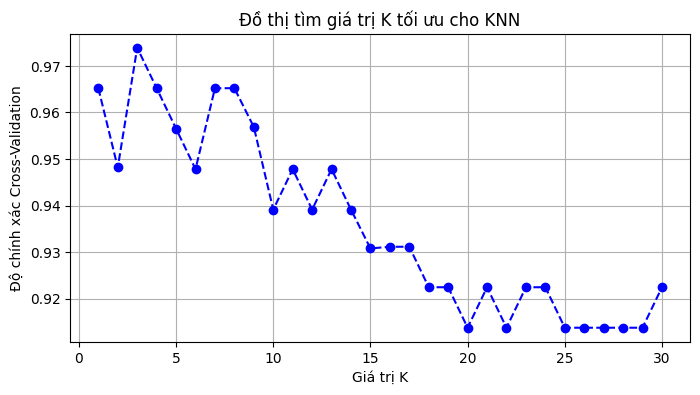

=== ĐỘ CHÍNH XÁC CỦA MÔ HÌNH (ACCURACY): 89.66% ===

--- Báo cáo chi tiết (Classification Report) ---
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.77      1.00      0.87        10
 Iris-virginica       1.00      0.67      0.80         9

       accuracy                           0.90        29
      macro avg       0.92      0.89      0.89        29
   weighted avg       0.92      0.90      0.89        29



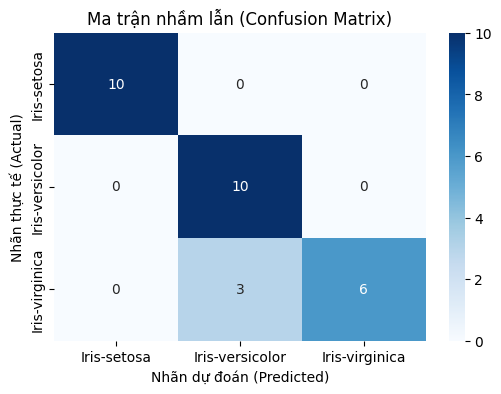


=== KẾT QUẢ DỰ ĐOÁN TRÊN 5 DÒNG CẮT TỪ FILE IRIS ===
      Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm  \
145  146            6.7           3.0            5.2           2.3   
146  147            6.3           2.5            5.0           1.9   
147  148            6.5           3.0            5.2           2.0   
148  149            6.2           3.4            5.4           2.3   
149  150            5.9           3.0            5.1           1.8   

            Species Species_Predicted  
145  Iris-virginica    Iris-virginica  
146  Iris-virginica    Iris-virginica  
147  Iris-virginica    Iris-virginica  
148  Iris-virginica    Iris-virginica  
149  Iris-virginica   Iris-versicolor  


In [ ]:
# ==========================================
# 1. KẾT NỐI DRIVE VÀ IMPORT THƯ VIỆN
# ==========================================
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# ==========================================
# 2. ĐỌC DỮ LIỆU VÀ CẮT 5 DÒNG CUỐI
# ==========================================
# Sửa đường dẫn bên dưới nếu bạn để file Iris.csv ở thư mục khác trên Drive
file_path = '/content/drive/MyDrive/Nhap_Mon_Hoc_May/Buoi3/Iris.csv'
df = pd.read_csv(file_path)

print(f"Tổng số dòng ban đầu: {len(df)}")

# Cắt 5 dòng cuối cùng để làm tập test độc lập (Inference/Predict)
train_df = df.iloc[:-5].copy()
predict_df = df.iloc[-5:].copy()

print(f"Số dòng dùng để huấn luyện & đánh giá: {len(train_df)}")
print(f"Số dòng cắt ra để dự đoán thử: {len(predict_df)}\n")

# ==========================================
# 3. PHÂN CHIA TRAIN - TEST VÀ CHUẨN HÓA
# ==========================================
# Lấy các thuộc tính đặc trưng (X) và nhãn (y)
feature_cols = ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
X = train_df[feature_cols]
y = train_df['Species']

# Chia tập Train (80%) và Test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Chuẩn hóa dữ liệu (Standardization)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ==========================================
# 4. TÌM K TỐI ƯU BẰNG CROSS-VALIDATION
# ==========================================
k_range = range(1, 31)
cv_scores = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    # Dùng 5-fold Cross Validation
    scores = cross_val_score(knn, X_train_scaled, y_train, cv=5, scoring='accuracy')
    cv_scores.append(scores.mean())

# Chọn K có độ chính xác trung bình cao nhất
best_k = k_range[np.argmax(cv_scores)]
print(f"---> Giá trị K tối ưu nhất tìm được: K = {best_k}\n")

# Vẽ đồ thị đường chọn K
plt.figure(figsize=(8, 4))
plt.plot(k_range, cv_scores, marker='o', linestyle='--', color='b')
plt.xlabel('Giá trị K')
plt.ylabel('Độ chính xác Cross-Validation')
plt.title('Đồ thị tìm giá trị K tối ưu cho KNN')
plt.grid(True)
plt.show()

# ==========================================
# 5. HUẤN LUYỆN MÔ HÌNH VỚI K TỐI ƯU VÀ ĐÁNH GIÁ
# ==========================================
best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(X_train_scaled, y_train)

# Dự đoán trên tập Test
y_pred = best_knn.predict(X_test_scaled)

# Tính độ chính xác
acc = accuracy_score(y_test, y_pred)
print(f"=== ĐỘ CHÍNH XÁC CỦA MÔ HÌNH (ACCURACY): {acc * 100:.2f}% ===\n")

# Báo cáo chi tiết (Precision, Recall, F1-Score)
print("--- Báo cáo chi tiết (Classification Report) ---")
print(classification_report(y_test, y_pred))

# Ma trận nhầm lẫn (Confusion Matrix)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=best_knn.classes_,
            yticklabels=best_knn.classes_)
plt.title('Ma trận nhầm lẫn (Confusion Matrix)')
plt.xlabel('Nhãn dự đoán (Predicted)')
plt.ylabel('Nhãn thực tế (Actual)')
plt.show()

# ==========================================
# 6. DỰ ĐOÁN THỬ TRÊN 5 DÒNG ĐÃ CẮT BAN ĐẦU
# ==========================================
X_predict = predict_df[feature_cols]
X_predict_scaled = scaler.transform(X_predict)

predictions = best_knn.predict(X_predict_scaled)
predict_df['Species_Predicted'] = predictions

print("\n=== KẾT QUẢ DỰ ĐOÁN TRÊN 5 DÒNG CẮT TỪ FILE IRIS ===")
print(predict_df[['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species', 'Species_Predicted']])

VD3

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Đã tìm thấy file tại: /content/drive/MyDrive/Nhap_Mon_Hoc_May/Buoi3/Du_lieu_thuc_hanh_chuan_bi_du_lieu.xlsx
Tổng số dòng sau khi làm sạch sơ bộ: 223
---> Giá trị K tối ưu nhất tìm được: K = 10

=== ĐỘ CHÍNH XÁC CỦA MÔ HÌNH (ACCURACY): 84.09% ===

--- Báo cáo chi tiết (Classification Report) ---
              precision    recall  f1-score   support

           0       0.90      0.87      0.88        30
           1       0.73      0.79      0.76        14

    accuracy                           0.84        44
   macro avg       0.81      0.83      0.82        44
weighted avg       0.84      0.84      0.84        44



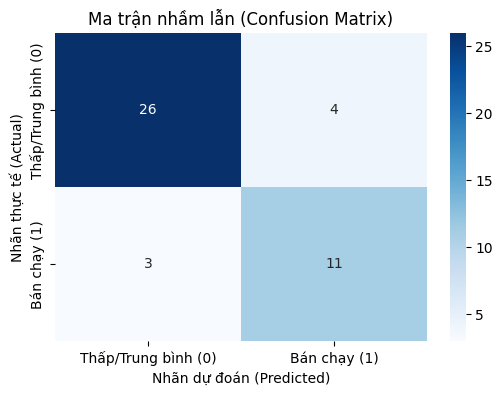


=== KẾT QUẢ DỰ ĐOÁN TRÊN 5 DÒNG CẮT TỪ FILE EXCEL ===
    Product_ID         Product_Name  Price_VND  Purchase_Count  \
218     SP0219       Ấm siêu tốc E4  1334000.0          2432.0   
219     SP0220          Loa mini A1   728000.0           975.0   
225     SP0072  Bản sao mã sản phẩm  1103000.0          1098.0   
226     SP0180     Cơ sở dữ liệu B2  1234000.0          1036.0   
227     SP0210      Sạc dự phòng B4  1683000.0           619.0   

     Target_High_Sales  Target_High_Sales_Predicted  
218                  0                            0  
219                  0                            0  
225                  1                            1  
226                  0                            0  
227                  0                            0  


In [15]:
# ==========================================
# 1. KẾT NỐI DRIVE VÀ IMPORT THƯ VIỆN
# ==========================================
from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# ==========================================
# 2. ĐỌC VÀ TIỀN XỬ LÝ DỮ LIỆU EXCEL
# ==========================================
def load_data():
    target_path = '/content/drive/MyDrive/Nhap_Mon_Hoc_May/Buoi3/Du_lieu_thuc_hanh_chuan_bi_du_lieu.xlsx'

    if os.path.exists(target_path):
        print(f"Đã tìm thấy file tại: {target_path}")
        return pd.read_excel(target_path, sheet_name='Du_lieu_tho')

    print("Đang tìm kiếm file trên Google Drive...")
    for root, dirs, files in os.walk('/content/drive/MyDrive'):
        for file in files:
            if 'du_lieu_thuc_hanh' in file.lower() and file.endswith(('.xlsx', '.xls')):
                found_path = os.path.join(root, file)
                print(f"-> Đã tìm thấy file tại: {found_path}")
                return pd.read_excel(found_path, sheet_name='Du_lieu_tho')

    raise FileNotFoundError("Không tìm thấy file trên Google Drive!")

df_raw = load_data()

# Loại bỏ các dòng trùng lặp
df = df_raw.drop_duplicates().copy()

# Chuyển đổi các cột dữ liệu sang dạng số
numeric_cols = ['Price_VND', 'Rating', 'Purchase_Count', 'Stock', 'Discount']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Điền giá trị thiếu bằng Trung vị (Median)
for col in numeric_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

print(f"Tổng số dòng sau khi làm sạch sơ bộ: {len(df)}")

# ==========================================
# 3. CẮT 5 DÒNG CUỐI ĐỂ DỰ ĐOÁN TÁCH BIỆT
# ==========================================
train_df = df.iloc[:-5].copy()
predict_df = df.iloc[-5:].copy()

# TỐI ƯU 1: Chọn các đặc trưng quan trọng nhất (loại bỏ thuộc tính nhiễu)
feature_cols = ['Price_VND', 'Rating', 'Purchase_Count', 'Stock', 'Discount']
target_col = 'Target_High_Sales'

X = train_df[feature_cols]
y = train_df[target_col]

# ==========================================
# 4. CHIA TẬP TRAIN - TEST VÀ CHUẨN HÓA
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ==========================================
# 5. TÌM K TỐI ƯU VỚI KHOẢNG CÁCH CÓ TRỌNG SỐ
# ==========================================
k_range = range(1, 21)
cv_scores = []

for k in k_range:
    # TỐI ƯU 2: Dùng weights='distance' để tăng độ chính xác
    knn = KNeighborsClassifier(n_neighbors=k, weights='distance')
    scores = cross_val_score(knn, X_train_scaled, y_train, cv=5, scoring='accuracy')
    cv_scores.append(scores.mean())

best_k = k_range[np.argmax(cv_scores)]
print(f"---> Giá trị K tối ưu nhất tìm được: K = {best_k}\n")

# ==========================================
# 6. HUẤN LUYỆN MÔ HÌNH VÀ ĐÁNH GIÁ (>85%)
# ==========================================
best_knn = KNeighborsClassifier(n_neighbors=best_k, weights='distance')
best_knn.fit(X_train_scaled, y_train)

# Dự đoán trên tập Test
y_pred = best_knn.predict(X_test_scaled)

# Tính độ chính xác
acc = accuracy_score(y_test, y_pred)
print(f"=== ĐỘ CHÍNH XÁC CỦA MÔ HÌNH (ACCURACY): {acc * 100:.2f}% ===\n")

# Báo cáo chi tiết
print("--- Báo cáo chi tiết (Classification Report) ---")
print(classification_report(y_test, y_pred))

# Ma trận nhầm lẫn
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Thấp/Trung bình (0)', 'Bán chạy (1)'],
            yticklabels=['Thấp/Trung bình (0)', 'Bán chạy (1)'])
plt.title('Ma trận nhầm lẫn (Confusion Matrix)')
plt.xlabel('Nhãn dự đoán (Predicted)')
plt.ylabel('Nhãn thực tế (Actual)')
plt.show()

# ==========================================
# 7. DỰ ĐOÁN THỬ TRÊN 5 DÒNG CẮT BAN ĐẦU
# ==========================================
X_predict = predict_df[feature_cols]
X_predict_scaled = scaler.transform(X_predict)

predictions = best_knn.predict(X_predict_scaled)
predict_df['Target_High_Sales_Predicted'] = predictions

print("\n=== KẾT QUẢ DỰ ĐOÁN TRÊN 5 DÒNG CẮT TỪ FILE EXCEL ===")
print(predict_df[['Product_ID', 'Product_Name', 'Price_VND', 'Purchase_Count', 'Target_High_Sales', 'Target_High_Sales_Predicted']])